# Phase 3 — Observation Operator and Source-to-Data Matrix
**Project:** Numerical Solution and PDE-Constrained Optimization of the Two-Dimensional Heat Equation  
**Goal:** Generate reproducible synthetic measurements and construct the forward observation matrix $A$. We **do not reconstruct** the unknown coefficients yet.

Model: $u_t-\alpha\Delta u=\sum_{r=1}^p\theta_r\phi_r(x,y)$ with zero initial and Dirichlet boundary data.

## 1. Mathematical construction
Let $u_r$ solve the forward PDE with source $\phi_r$ and zero initial/boundary data. For measurement coordinates $(x_k,y_k,t_k)$ define

$$A_{kr}=u_r(x_k,y_k,t_k), \qquad d_k^{\mathrm{clean}}=u_{\theta^\star}(x_k,y_k,t_k).$$

Linearity gives $\mathbf d^{\mathrm{clean}}=A\boldsymbol\theta^\star$, up to numerical roundoff **provided that we use the same grid, timesteps, and discrete observation rule** for both calculations. Then set $\mathbf d^{\mathrm{noisy}}=\mathbf d^{\mathrm{clean}}+\boldsymbol\varepsilon$, where $\varepsilon_k\sim\mathcal n(0,\sigma_\varepsilon^2)$ independently. Here $\sigma_\varepsilon=0.01\max_k|d_k^{\mathrm{clean}}|$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import ceil

def gaussian_source(X, Y, amplitude=1., center=(.5,.5), sigma=.1):
    a,b = center
    return amplitude * np.exp(-((X-a)**2+(Y-b)**2)/(2*sigma**2))

def solve_heat_2d(source, nx=32, ny=32, alpha=.1, T=.1,
                  snapshot_fractions=(0.,.25,.5,1.), stability_fraction=.9):
    """Return x, y, dt, nt and {time_step: U} for the FTCS forward PDE."""
    assert nx>=2 and ny>=2 and alpha>0 and T>0 and 0<stability_fraction<=1
    x=np.linspace(0,1,nx+1); y=np.linspace(0,1,ny+1)
    X,Y=np.meshgrid(x,y,indexing='ij')
    F=np.asarray(source(X,Y) if callable(source) else source,dtype=float)
    assert F.shape==X.shape and np.isfinite(F).all()
    hx,hy=1/nx,1/ny
    dt_max=.5/(alpha*(1/hx**2+1/hy**2))
    nt=max(1,ceil(T/(stability_fraction*dt_max)));dt=T/nt
    rx=alpha*dt/hx**2;ry=alpha*dt/hy**2
    assert rx+ry<=.5+1e-12
    wanted={round(frac*nt) for frac in snapshot_fractions}
    U=np.zeros_like(F); snaps={0:U.copy()} if 0 in wanted else {}
    for n in range(nt):
        V=np.zeros_like(U)
        V[1:-1,1:-1]=(U[1:-1,1:-1]
           +rx*(U[2:,1:-1]-2*U[1:-1,1:-1]+U[:-2,1:-1])
           +ry*(U[1:-1,2:]-2*U[1:-1,1:-1]+U[1:-1,:-2])
           +dt*F[1:-1,1:-1])
        U=V
        if n+1 in wanted:snaps[n+1]=U.copy()
    return x,y,dt,nt,snaps

## 2. Fix source basis, true coefficients, measurement locations and times
The 16 spatial sensors are located at exact grid nodes, so no interpolation is required. Each sensor is sampled at three time steps nearest to $T/4$, $T/2$, and $T$; actual times are computed from the discretized time grid.

In [ ]:
nx=ny=32; alpha=.1; T=.1
centers=[(.25,.28),(.72,.35),(.53,.76)]
widths=[.10,.12,.09]
theta_true=np.array([1.2,.85,1.05]); p=len(theta_true)
x=np.linspace(0,1,nx+1);y=np.linspace(0,1,ny+1)
X,Y=np.meshgrid(x,y,indexing='ij')
basis=[gaussian_source(X,Y,center=c,sigma=s) for c,s in zip(centers,widths)]
sensor_indices=[(i,j) for i in (5,12,20,27) for j in (5,12,20,27)]
fractions=(0.,.25,.5,1.)
responses=[solve_heat_2d(phi,nx,ny,alpha,T,fractions) for phi in basis]
dt,nt=responses[0][2:4]
steps=[round(frac*nt) for frac in fractions[1:]]
t_obs=np.array(steps)*dt
print('Time steps:',nt,'| dt:',dt,'| actual observation times:',t_obs)
print('Number of observations:',len(sensor_indices)*len(steps))

Time steps: 46 | dt: 0.002173913043478261 | actual observation times: [0.02608696 0.05       0.1       ]
Number of observations: 48


## 3. Define discrete observation operator and assemble $A$
Rows are ordered by observation time and then by the sensor order in `sensor_indices`. Column $r$ is the measured response to source $\phi_r$.

In [ ]:
def observe(snapshot_dict, steps, sensors):
    return np.array([snapshot_dict[k][i,j] for k in steps for i,j in sensors])

A=np.column_stack([observe(response[-1],steps,sensor_indices) for response in responses])
source_true=sum(c*phi for c,phi in zip(theta_true,basis))
_,_,_,_,direct_snapshots=solve_heat_2d(source_true,nx,ny,alpha,T,fractions)
d_clean=observe(direct_snapshots,steps,sensor_indices)
d_from_matrix=A@theta_true
superposition_error=np.max(np.abs(d_clean-d_from_matrix))
print('A.shape:',A.shape)
print('rank(A):',np.linalg.matrix_rank(A),'| cond(A):',np.linalg.cond(A))
print('max |direct PDE observations - A @ theta_true|:',superposition_error)
assert A.shape==(48,3)
assert np.linalg.matrix_rank(A)==3
assert superposition_error<1e-12

A.shape: (48, 3)
rank(A): 3 | cond(A): 1.8063590725990064
max |direct PDE observations - A @ theta_true|: 2.0816681711721685e-17


## 4. Add measurement noise (reproducibly)
The **clean data are simulated**, not analytically measured. This phase checks discrete superposition, not analytical PDE error for arbitrary Gaussian sources.

In [ ]:
rng=np.random.default_rng(2026)
noise_std=.01*np.max(np.abs(d_clean))
noise=rng.normal(0,noise_std,size=d_clean.shape)
d_noisy=d_clean+noise
print('Noise standard deviation:',noise_std)
print('Observed realization relative noise norm:',np.linalg.norm(noise)/np.linalg.norm(d_clean))
assert np.allclose(d_noisy-d_clean,noise)

Noise standard deviation: 0.0004510500312555989
Observed realization relative noise norm: 0.021918758051885652


## 5. Plot sources, response, sensor locations and measurements

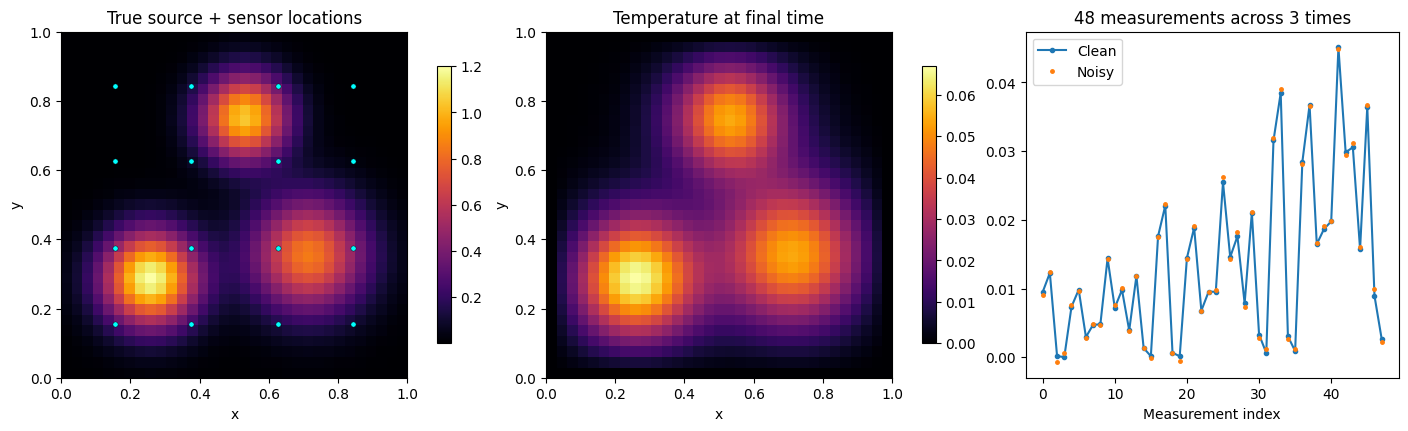

In [ ]:
fig,axs=plt.subplots(1,3,figsize=(14,4.2),constrained_layout=True)
im=axs[0].imshow(source_true.T,origin='lower',extent=[0,1,0,1],cmap='inferno')
axs[0].scatter([x[i] for i,j in sensor_indices],[y[j] for i,j in sensor_indices],s=14,c='cyan',edgecolors='black',linewidths=.3)
axs[0].set_title('True source + sensor locations');fig.colorbar(im,ax=axs[0],shrink=.8)
im=axs[1].imshow(direct_snapshots[steps[-1]].T,origin='lower',extent=[0,1,0,1],cmap='inferno')
axs[1].set_title('Temperature at final time');fig.colorbar(im,ax=axs[1],shrink=.8)
axs[2].plot(d_clean,'o-',ms=3,label='Clean');axs[2].plot(d_noisy,'.',ms=5,label='Noisy')
axs[2].set_title('48 measurements across 3 times');axs[2].set_xlabel('Measurement index');axs[2].legend()
for ax in axs[:2]:ax.set(xlabel='x',ylabel='y')
plt.show()

## 6. Sanity checks and data export
We save the response matrix, observation vectors, and metadata for Phase 4. Do **not** fit $\theta$ here: that is the next phase.

In [ ]:
assert all(np.allclose(direct_snapshots[k][0,:],0) and np.allclose(direct_snapshots[k][:,0],0)
           and np.allclose(direct_snapshots[k][-1,:],0) and np.allclose(direct_snapshots[k][:,-1],0)
           for k in steps)
np.savez('phase3_observation_data.npz',A=A,theta_true=theta_true,d_clean=d_clean,
         d_noisy=d_noisy,noise=noise,sensor_indices=np.array(sensor_indices),
         step_indices=np.array(steps),t_obs=t_obs,x=x,y=y,basis=np.stack(basis),
         source_true=source_true,temperature_final=direct_snapshots[steps[-1]],
         nx=nx,ny=ny,alpha=alpha,T=T,dt=dt,nt=nt)
print('All checks passed; saved phase3_observation_data.npz')

All checks passed; saved phase3_observation_data.npz
